# Phase 3 - OCR Foundations
## What problem are we solving?
In Phase 3, we are solving the recognition problem: given a canonical, rectified identity-document image, extract the seven required identity fields into a structured output using a modular OCR-based pipeline.

Can we reliably transform known field regions from a rectified alb_id document into normalized structured values such as document number, surname, date of birth, and nationality, while measuring accuracy and inference cost?
## Audit the Identity split

Before using any image, we need to verify which identities belong to training, validation and test.

In [1]:
from pathlib import Path

import pandas as pd


current_directory = Path.cwd().resolve()

if (current_directory / "PROJECT.md").is_file():
    repository_root = current_directory
elif (current_directory.parent / "PROJECT.md").is_file():
    repository_root = current_directory.parent
else:
    raise FileNotFoundError(
        "Start Jupyter from the repository root or notebooks directory."
    )

split_manifest_path = (
    repository_root
    / "splits"
    / "alb_id_v1.csv"
)

print("Repository root:", repository_root)
print("Split manifest:", split_manifest_path)

Repository root: /home/raspiestchip/kyc-router
Split manifest: /home/raspiestchip/kyc-router/splits/alb_id_v1.csv


In [2]:
split_manifest = pd.read_csv(
    split_manifest_path,
    dtype={"sample_id": "string"},
)

print("Shape:", split_manifest.shape)
print("Columns:", split_manifest.columns.tolist())

split_manifest.head()



Shape: (100, 5)
Columns: ['identity_key', 'document_type', 'sample_id', 'split', 'split_seed']


,identity_key,document_type,sample_id,split,split_seed
0,alb_id/38,alb_id,38,train,2026
1,alb_id/06,alb_id,06,train,2026
2,alb_id/77,alb_id,77,train,2026
3,alb_id/69,alb_id,69,train,2026
4,alb_id/02,alb_id,02,train,2026


In [3]:
split_counts = split_manifest["split"].value_counts()

print(split_counts)

assert len(split_manifest) == 100
assert split_manifest["identity_key"].is_unique
assert split_manifest["sample_id"].is_unique

assert split_counts.to_dict() == {
    "train": 70,
    "validation": 15,
    "test": 15,
}


split
train         70
validation    15
test          15
Name: count, dtype: int64


Let's select one training identity:

In [4]:

training_manifest = (
    split_manifest
    .loc[split_manifest["split"] == "train"]
    .sort_values("sample_id")
    .reset_index(drop=True)
)

training_row = training_manifest.iloc[0]

training_identity_key = training_row["identity_key"]
training_document_type = training_row["document_type"]
training_sample_id = training_row["sample_id"]

print("Selected identity:", training_identity_key)
print("Document type:", training_document_type)
print("Sample ID:", training_sample_id)

Selected identity: alb_id/02
Document type: alb_id
Sample ID: 02


Let's compare the clean template with the unprocessed photograph.


## One identity, two observations

The clean template and photograph contain the same identity, but they are
different observations:

- The template is a clean digital document image.
- The photograph contains perspective, background, lighting, and capture
  artifacts.

The template annotations contain field rectangles and ground-truth text.
The photograph annotations contain the document quadrilateral used for
rectification

In [5]:
import json

import cv2
import matplotlib.pyplot as plt


dataset_root = repository_root / "data" / "raw"
training_filename = f"{training_sample_id}.jpg"

template_image_path = (
    dataset_root
    / "templates"
    / "images"
    / training_document_type
    / training_filename
)

photo_image_path = (
    dataset_root
    / "photo"
    / "images"
    / training_document_type
    / training_filename
)

template_annotation_path = (
    dataset_root
    / "templates"
    / "annotations"
    / f"{training_document_type}.json"
)

photo_annotation_path = (
    dataset_root
    / "photo"
    / "annotations"
    / f"{training_document_type}.json"
)

for path in (
    template_image_path,
    photo_image_path,
    template_annotation_path,
    photo_annotation_path,
):
    assert path.is_file(), f"Missing file: {path}"

print("Template:", template_image_path)
print("Photograph:", photo_image_path)


Template: /home/raspiestchip/kyc-router/data/raw/templates/images/alb_id/02.jpg
Photograph: /home/raspiestchip/kyc-router/data/raw/photo/images/alb_id/02.jpg


In [6]:
template_bgr = cv2.imread(str(template_image_path))
photo_bgr = cv2.imread(str(photo_image_path))

assert template_bgr is not None
assert photo_bgr is not None

print("Template shape:", template_bgr.shape)
print("Photograph shape:", photo_bgr.shape)
print("Template dtype:", template_bgr.dtype)
print("Photograph dtype:", photo_bgr.dtype)

Template shape: (1360, 2167, 3)
Photograph shape: (4032, 2268, 3)
Template dtype: uint8
Photograph dtype: uint8


In [7]:
with template_annotation_path.open(encoding="utf-8") as annotation_file:
    template_metadata = json.load(annotation_file)["_via_img_metadata"]

with photo_annotation_path.open(encoding="utf-8") as annotation_file:
    photo_metadata = json.load(annotation_file)["_via_img_metadata"]


template_record = next(
    (
        record
        for record in template_metadata.values()
        if record["filename"] == training_filename
    ),
    None,
)

photo_record = next(
    (
        record
        for record in photo_metadata.values()
        if record["filename"] == training_filename
    ),
    None,
)

assert template_record is not None
assert photo_record is not None

In [8]:
template_field_names = [
    region["region_attributes"].get("field_name")
    for region in template_record["regions"]
]

photo_field_names = [
    region["region_attributes"].get("field_name")
    for region in photo_record["regions"]
]

print("Template fields:")
print(template_field_names)

print("\nPhotograph fields:")
print(photo_field_names)

Template fields:
['photo', 'signature', 'authority', 'birth_date', 'birth_place', 'issue_date', 'expiry_date', 'gender', 'id_number', 'name', 'nationality', 'number', 'surname', 'face']

Photograph fields:
['face', 'doc_quad']


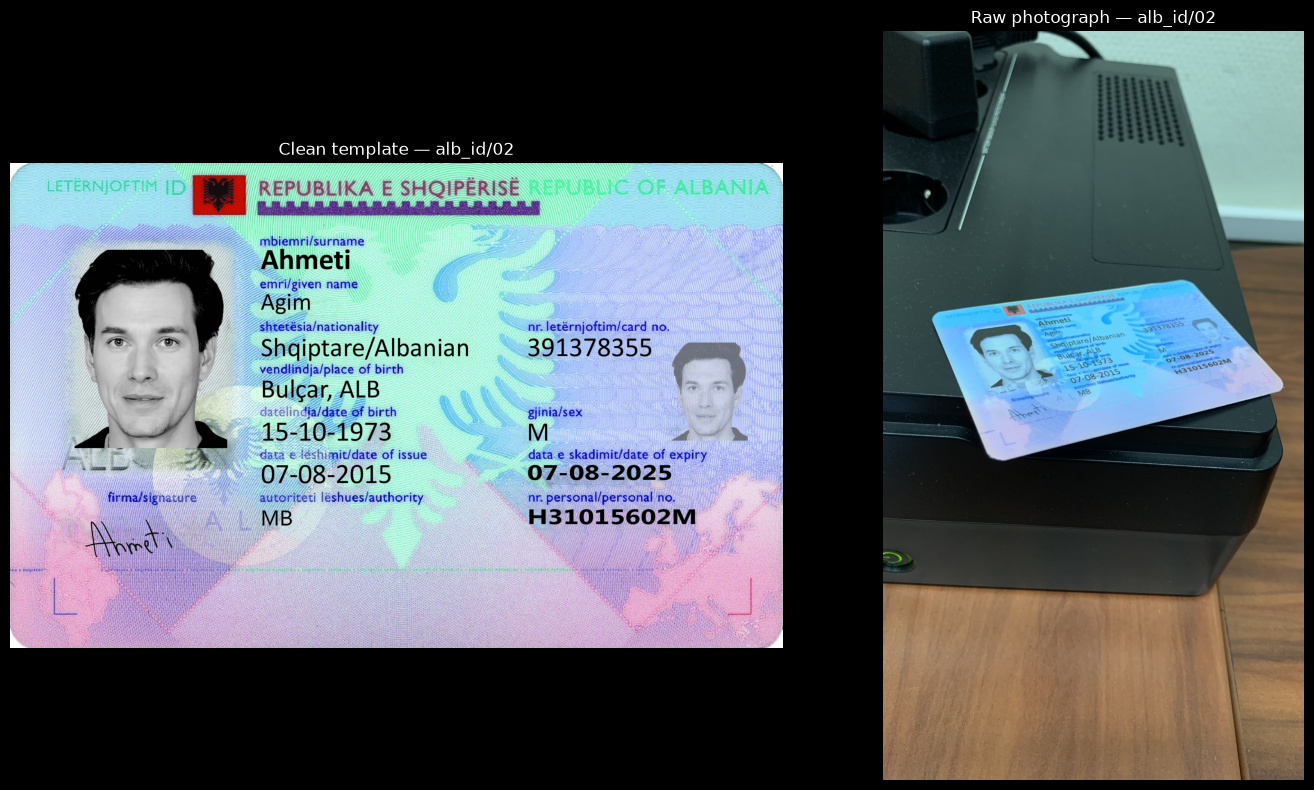

In [9]:
template_rgb = cv2.cvtColor(template_bgr, cv2.COLOR_BGR2RGB)
photo_rgb = cv2.cvtColor(photo_bgr, cv2.COLOR_BGR2RGB)

figure, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].imshow(template_rgb)
axes[0].set_title(f"Clean template — {training_identity_key}")
axes[0].axis("off")

axes[1].imshow(photo_rgb)
axes[1].set_title(f"Raw photograph — {training_identity_key}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Selecting the Recognizer

## Runtime environment

OCR model selection depends partly on the available hardware and libraries.

A larger model might improve recognition, but it also requires more memory and
increases latency. Because latency is one of our experimental measurements, the
execution device and numerical precision must be recorded.


In [10]:
from importlib.util import find_spec
import platform
import sys


torch_available = find_spec("torch") is not None
transformers_available = find_spec("transformers") is not None

print("Python:", sys.version.split()[0])
print("Operating system:", platform.platform())
print("PyTorch installed:", torch_available)
print("Transformers installed:", transformers_available)

if torch_available:
    import torch

    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("CUDA version:", torch.version.cuda)
        print("GPU:", torch.cuda.get_device_name(0))
        print(
            "GPU memory:",
            round(
                torch.cuda.get_device_properties(0).total_memory / 1024**3,
                2,
            ),
            "GiB",
        )
    else:
        print("Inference device: CPU")

if transformers_available:
    import transformers

    print("Transformers version:", transformers.__version__)

Python: 3.14.7
Operating system: Linux-7.2.5-200.fc44.x86_64-x86_64-with-glibc2.43
PyTorch installed: True
Transformers installed: True
PyTorch version: 2.14.1+cu130
CUDA available: True
CUDA version: 13.0
GPU: NVIDIA GeForce GTX 1650
GPU memory: 3.64 GiB


/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformers version: 5.19.0


## Install the OCR dependencies

The OCR baseline requires:

- PyTorch for tensor operations and model execution;
- Transformers for the TrOCR implementation;
- SentencePiece for the model's tokenizer.


Verify the required runtime and install the missing pieces:

In [11]:
import sentencepiece
import torch
import torchvision
import transformers


assert torch.cuda.is_available(), (
    "PyTorch cannot access CUDA. Do not continue with model loading."
)

cuda_device_index = 0
inference_device = torch.device(
    f"cuda:{cuda_device_index}"
)

gpu_properties = torch.cuda.get_device_properties(
    cuda_device_index
)

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("Transformers:", transformers.__version__)
print("SentencePiece:", sentencepiece.__version__)

print("\nPyTorch CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("Inference device:", inference_device)
print("GPU:", gpu_properties.name)
print(
    "GPU memory:",
    round(gpu_properties.total_memory / 1024**3, 2),
    "GiB",
)


PyTorch: 2.14.1+cu130
TorchVision: 0.29.1+cu130
Transformers: 5.19.0
SentencePiece: 0.2.2

PyTorch CUDA runtime: 13.0
CUDA available: True
Inference device: cuda:0
GPU: NVIDIA GeForce GTX 1650
GPU memory: 3.64 GiB


Let's execute a real CUDA operation in PyTorch as a final check:

In [12]:
cuda_test_tensor = torch.tensor(
    [1.0, 2.0, 3.0],
    device=inference_device,
)

cuda_test_result = (cuda_test_tensor ** 2).sum()

print("Tensor device:", cuda_test_tensor.device)
print("Result:", cuda_test_result.item())

assert cuda_test_result.item() == 14.0

print("CUDA computation passed.")

Tensor device: cuda:0
Result: 14.0
CUDA computation passed.


Now we can start playing with OCRs. But first...

## What's OCR?

Optical Character Recognition, or OCR, converts texts represented as image pixels into machine-readable characters.

A complete OCR system can contain several separate problems:

1. Document localization — find the document inside the photograph.
2. Rectification — transform the document into a flat canonical view.
3. Text detection — find regions containing text.
4. Text recognition — convert each text-region image into characters.
5. Post-processing — normalize, validate, and organize recognized text.
6. Structured extraction — map recognized values into fields such as surname
   or date of birth.

Our project does not ask the OCR model to solve every stage.

Phase 2 and the MIDV annotations already provide document rectification and
known field locations. Phase 3 therefore concentrates on text recognition,
normalization, validation, and structured output.

You can see more detailed explanations at /docs/learning/OCR.md but here's a distinction between some OCR strategies:

In [13]:
ocr_strategy_comparison = pd.DataFrame(
    [
        {
            "strategy": "Character segmentation",
            "input": "Character image",
            "alignment": "Explicit character regions",
            "output": "Character class",
            "main_tradeoff": "Sensitive to segmentation errors",
        },
        {
            "strategy": "CNN/RNN + CTC",
            "input": "Text-line image",
            "alignment": "Learned implicitly by CTC",
            "output": "Character sequence",
            "main_tradeoff": "Efficient but has a constrained decoding model",
        },
        {
            "strategy": "TrOCR encoder-decoder",
            "input": "Text-line image",
            "alignment": "Attention between decoder and image representation",
            "output": "Generated token sequence",
            "main_tradeoff": "Flexible but autoregressive and potentially slower",
        },
        {
            "strategy": "Donut",
            "input": "Entire document",
            "alignment": "No explicit OCR alignment",
            "output": "Serialized structured data",
            "main_tradeoff": "Requires task-specific document training",
        },
    ]
)

ocr_strategy_comparison

,strategy,input,alignment,output,main_tradeoff
0,Character segmentation,Character image,Explicit character regions,Character class,Sensitive to segmentation errors
1,CNN/RNN + CTC,Text-line image,Learned implicitly by CTC,Character sequence,Efficient but has a constrained decoding model
2,TrOCR encoder-decoder,Text-line image,Attention between decoder and image representa...,Generated token sequence,Flexible but autoregressive and potentially sl...
3,Donut,Entire document,No explicit OCR alignment,Serialized structured data,Requires task-specific document training


## The OCR Checkpoint

The first baseline uses `microsoft/trocr-small-printed`.

TrOCR has three important components:

1. The processor transforms an RGB image into the tensor expected by the model.
   It also contains the tokenizer used to decode token IDs into text.
2. The vision encoder converts image patches into contextual visual
   representations.
3. The autoregressive decoder generates text tokens one at a time while
   attending to the encoder's visual representation.

This checkpoint is suitable for printed, single-line crops, but it was trained
on receipt text rather than identity documents. Its performance on MIDV is
therefore an experimental question.


In [14]:
ocr_model_id = "microsoft/trocr-small-printed"
ocr_model_revision = "04e994ab854b0089d4929f48c2b4dbe2ce78a340"

print("Model:", ocr_model_id)
print("Revision:", ocr_model_revision)

# The revision is an immutable commit, preventing a future update to main from silently changing our model.


Model: microsoft/trocr-small-printed
Revision: 04e994ab854b0089d4929f48c2b4dbe2ce78a340


In [16]:
from transformers import (
    GenerationConfig,
    TrOCRProcessor,
    VisionEncoderDecoderConfig,
)


ocr_processor = TrOCRProcessor.from_pretrained(
    ocr_model_id,
    revision=ocr_model_revision,
)

ocr_model_config = VisionEncoderDecoderConfig.from_pretrained(
    ocr_model_id,
    revision=ocr_model_revision,
)

ocr_generation_config = GenerationConfig.from_pretrained(
    ocr_model_id,
    revision=ocr_model_revision,
)

In [17]:
ocr_image_processor = ocr_processor.image_processor
ocr_tokenizer = ocr_processor.tokenizer

ocr_encoder_config = ocr_model_config.encoder
ocr_decoder_config = ocr_model_config.decoder

print("Processor:", type(ocr_processor).__name__)
print("Image processor:", type(ocr_image_processor).__name__)
print("Tokenizer:", type(ocr_tokenizer).__name__)

print("\nEncoder type:", ocr_encoder_config.model_type)
print("Decoder type:", ocr_decoder_config.model_type)

Processor: TrOCRProcessor
Image processor: DeiTImageProcessor
Tokenizer: XLMRobertaTokenizer

Encoder type: deit
Decoder type: trocr


In [18]:

print("Expected image size:", ocr_image_processor.size)
print("Image mean:", ocr_image_processor.image_mean)
print("Image standard deviation:", ocr_image_processor.image_std)

print("\nEncoder image size:", ocr_encoder_config.image_size)
print("Encoder patch size:", ocr_encoder_config.patch_size)
print("Encoder hidden size:", ocr_encoder_config.hidden_size)
print("Encoder layers:", ocr_encoder_config.num_hidden_layers)

Expected image size: SizeDict(height=384, width=384, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Image mean: (0.5, 0.5, 0.5)
Image standard deviation: (0.5, 0.5, 0.5)

Encoder image size: 384
Encoder patch size: 16
Encoder hidden size: 384
Encoder layers: 12


In [20]:
print("Expected image size:", ocr_image_processor.size)
print("Image mean:", ocr_image_processor.image_mean)
print("Image standard deviation:", ocr_image_processor.image_std)

print("\nEncoder image size:", ocr_encoder_config.image_size)
print("Encoder patch size:", ocr_encoder_config.patch_size)
print("Encoder hidden size:", ocr_encoder_config.hidden_size)
print("Encoder layers:", ocr_encoder_config.num_hidden_layers)

# If the image size is 384 and patch size is 16, the encoder divides the image into:

patches_per_side = (
    ocr_encoder_config.image_size
    // ocr_encoder_config.patch_size
)

image_patch_count = patches_per_side ** 2

print("Patches per side:", patches_per_side)
print("Image patch count:", image_patch_count)

Expected image size: SizeDict(height=384, width=384, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Image mean: (0.5, 0.5, 0.5)
Image standard deviation: (0.5, 0.5, 0.5)

Encoder image size: 384
Encoder patch size: 16
Encoder hidden size: 384
Encoder layers: 12
Patches per side: 24
Image patch count: 576


In [21]:
print("Tokenizer vocabulary:", ocr_tokenizer.vocab_size)
print("Decoder vocabulary:", ocr_decoder_config.vocab_size)
print("Decoder hidden size:", ocr_decoder_config.d_model)
print("Decoder layers:", ocr_decoder_config.decoder_layers)

print("\nGeneration settings:")
print("Maximum length:", ocr_generation_config.max_length)
print("Number of beams:", ocr_generation_config.num_beams)
print("Sampling enabled:", ocr_generation_config.do_sample)


Tokenizer vocabulary: 64002
Decoder vocabulary: 64044
Decoder hidden size: 256
Decoder layers: 6

Generation settings:
Maximum length: None
Number of beams: None
Sampling enabled: None


# First single-crop inference

### Load the learned model weights

Before running inference, distinguish configuration from weights:
- Configuration describes the architecture.
- Weights contain the learned numerical parameters.
- Loading the processor earlier did not load these model weights.

After loading, the model is moved to the GPU and placed in evaluation mode.
Evaluation mode disables training-specific behavior such as dropout, making
inference deterministic for fixed inputs and decoding settings.

In [23]:
from transformers import VisionEncoderDecoderModel


torch.cuda.reset_peak_memory_stats(
    inference_device
)

gpu_memory_before_load = torch.cuda.memory_allocated(
    inference_device
)

ocr_model = VisionEncoderDecoderModel.from_pretrained(
    ocr_model_id,
    revision=ocr_model_revision,
    dtype=torch.float32,
    use_safetensors=True,
)

ocr_model = ocr_model.to(inference_device)
ocr_model.eval()

gpu_memory_after_load = torch.cuda.memory_allocated(
    inference_device
)

Loading weights: 100%|██████████| 360/360 [00:00<00:00, 16490.29it/s]
[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [26]:
total_parameter_count = sum(
    parameter.numel()
    for parameter in ocr_model.parameters()
)

model_parameter_bytes = sum(
    parameter.numel() * parameter.element_size()
    for parameter in ocr_model.parameters()
)

model_parameter_memory_mib = (
    model_parameter_bytes / 1024**2
)

gpu_memory_increase_mib = (
    gpu_memory_after_load - gpu_memory_before_load
) / 1024**2

print(f"Parameters: {total_parameter_count:,}")
print(
    "Parameter storage:",
    round(model_parameter_memory_mib, 2),
    "MiB",
)

print(
    "PyTorch GPU-memory increase:",
    round(gpu_memory_increase_mib, 2),
    "MiB",
)

print(
    "Peak PyTorch GPU memory:",
    round(
        torch.cuda.max_memory_allocated(inference_device)
        / 1024**2,
        2,
    ),
    "MiB",
)

print(
    "Model device:",
    next(ocr_model.parameters()).device,
)

print("Training mode:", ocr_model.training)

Parameters: 61,596,672
Parameter storage: 234.97 MiB
PyTorch GPU-memory increase: 0.0 MiB
Peak PyTorch GPU memory: 235.85 MiB
Model device: cuda:0
Training mode: False


In [27]:

assert next(ocr_model.parameters()).device == inference_device
assert ocr_model.training is False

print("Model is loaded on the GPU in evaluation mode.")

Model is loaded on the GPU in evaluation mode.



## From field crop to encoder representations

For one field, we will inspect three representations:

1. The original RGB crop: unsigned integer pixels from 0 to 255.
2. The processor output: a normalized floating-point tensor.
3. The encoder output: one contextual vector for every image token.

This lets us inspect the model input before asking the decoder to generate text.


In [29]:
import json


phase_2_config_path = (
    repository_root
    / "configs"
    / "controlled_degradations_v1.json"
)

with phase_2_config_path.open(encoding="utf-8") as config_file:
    phase_2_config = json.load(config_file)

canonical_width = phase_2_config["canonical_width"]
canonical_height = phase_2_config["canonical_height"]

print("Canonical size:", canonical_width, "×", canonical_height)

Canonical size: 1084 × 680


In [31]:
clean_canonical_bgr = cv2.resize(
    template_bgr,
    (canonical_width, canonical_height),
    interpolation=cv2.INTER_AREA,
)

clean_canonical_rgb = cv2.cvtColor(
    clean_canonical_bgr,
    cv2.COLOR_BGR2RGB,
)

assert clean_canonical_rgb.shape == (
    canonical_height,
    canonical_width,
    3,
)

In [33]:
selected_field_name = "surname"

selected_field_region = next(
    region
    for region in template_record["regions"]
    if region["region_attributes"].get("field_name")
    == selected_field_name
)

selected_field_ground_truth = (
    selected_field_region["region_attributes"]["value"]
)

native_field_shape = selected_field_region["shape_attributes"]

template_height, template_width = template_bgr.shape[:2]

scale_x = canonical_width / template_width
scale_y = canonical_height / template_height

canonical_field_shape = {
    "x": round(native_field_shape["x"] * scale_x),
    "y": round(native_field_shape["y"] * scale_y),
    "width": round(native_field_shape["width"] * scale_x),
    "height": round(native_field_shape["height"] * scale_y),
}

print("Ground truth:", selected_field_ground_truth)
print("Native rectangle:", native_field_shape)
print("Canonical rectangle:", canonical_field_shape)

Ground truth: Ahmeti
Native rectangle: {'name': 'rect', 'x': 703, 'y': 242, 'width': 251, 'height': 55}
Canonical rectangle: {'x': 352, 'y': 121, 'width': 126, 'height': 28}


In [35]:
## Apply padding
field_padding_x = 0.10
field_minimum_padding_x = 12
field_padding_top = 0.10
field_padding_bottom = 0.40

field_x = canonical_field_shape["x"]
field_y = canonical_field_shape["y"]
field_width = canonical_field_shape["width"]
field_height = canonical_field_shape["height"]

horizontal_padding = max(
    round(field_width * field_padding_x),
    field_minimum_padding_x,
)

top_padding = round(
    field_height * field_padding_top
)

bottom_padding = round(
    field_height * field_padding_bottom
)

crop_x1 = max(0, field_x - horizontal_padding)
crop_y1 = max(0, field_y - top_padding)

crop_x2 = min(
    canonical_width,
    field_x + field_width + horizontal_padding,
)

crop_y2 = min(
    canonical_height,
    field_y + field_height + bottom_padding,
)

selected_field_crop_rgb = clean_canonical_rgb[
    crop_y1:crop_y2,
    crop_x1:crop_x2,
]

assert selected_field_crop_rgb.size > 0

print("Crop shape:", selected_field_crop_rgb.shape)
print("Crop dtype:", selected_field_crop_rgb.dtype)

Crop shape: (42, 152, 3)
Crop dtype: uint8


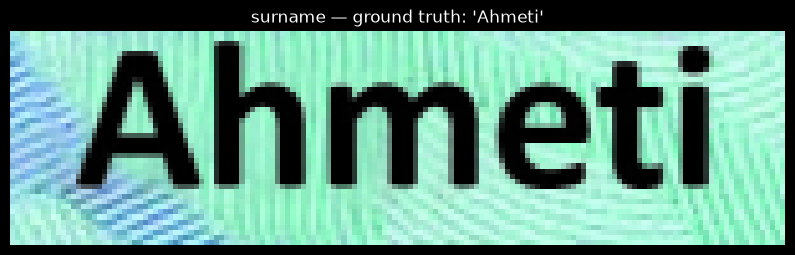

In [37]:
# Inspecting

plt.figure(figsize=(10, 3))
plt.imshow(selected_field_crop_rgb)
plt.title(
    f"{selected_field_name} — "
    f"ground truth: {selected_field_ground_truth!r}"
)
plt.axis("off")
plt.show()

In [38]:
# Loading the model
processed_field_crop = ocr_processor(
    images=selected_field_crop_rgb,
    return_tensors="pt",
)

field_pixel_values_cpu = (
    processed_field_crop.pixel_values
)

print("Tensor shape:", field_pixel_values_cpu.shape)
print("Tensor dtype:", field_pixel_values_cpu.dtype)
print("Tensor device:", field_pixel_values_cpu.device)
print("Minimum value:", field_pixel_values_cpu.min().item())
print("Maximum value:", field_pixel_values_cpu.max().item())
print("Mean value:", field_pixel_values_cpu.mean().item())

Tensor shape: torch.Size([1, 3, 384, 384])
Tensor dtype: torch.float32
Tensor device: cpu
Minimum value: -1.0
Maximum value: 1.0
Mean value: 0.2275322675704956


The dimensions mean: batch, color channels, height, width

The processor resizes the rectangular crop into the model's square input and normalizes its pixel values.

Let's now move the tensor to the GPU:

In [40]:
field_pixel_values_gpu = (
    field_pixel_values_cpu.to(inference_device)
)

assert field_pixel_values_gpu.device == inference_device

print("GPU tensor device:", field_pixel_values_gpu.device)

GPU tensor device: cuda:0


### Running the vision encoder



In [41]:
with torch.inference_mode():
    field_encoder_outputs = ocr_model.encoder(
        pixel_values=field_pixel_values_gpu,
        return_dict=True,
    )

field_encoder_hidden_states = (
    field_encoder_outputs.last_hidden_state
)

print(
    "Encoder output shape:",
    field_encoder_hidden_states.shape,
)

print(
    "Encoder output dtype:",
    field_encoder_hidden_states.dtype,
)

print(
    "Encoder output device:",
    field_encoder_hidden_states.device,
)

Encoder output shape: torch.Size([1, 578, 384])
Encoder output dtype: torch.float32
Encoder output device: cuda:0


- 1: one image;
- 578: 576 image patches plus two special DeiT tokens;
- 384: learned values describing each token in context.

In [42]:
encoder_token_count = (
    field_encoder_hidden_states.shape[1]
)

encoder_hidden_size = (
    field_encoder_hidden_states.shape[2]
)

special_image_token_count = (
    encoder_token_count - image_patch_count
)

print("Image patches:", image_patch_count)
print("Special image tokens:", special_image_token_count)
print("Encoder hidden size:", encoder_hidden_size)


Image patches: 576
Special image tokens: 2
Encoder hidden size: 384


## Autoregressive text generation

The encoder processes the image once. The decoder then generates a sequence
iteratively:

1. Start with a special decoder token.
2. Predict scores for every token in the vocabulary.
3. Select the next token.
4. Append that token to the sequence.
5. Repeat until an end token or length limit is reached.

The generated values are token IDs. They must be decoded through the
checkpoint's tokenizer before they become text.

A token is not necessarily one character. It may represent a character,
punctuation mark, common substring, or complete word fragment.


In [43]:
with torch.inference_mode():
    generated_field_token_ids = ocr_model.generate(
        pixel_values=field_pixel_values_gpu,
        generation_config=ocr_generation_config,
    )

print("Generated shape:", generated_field_token_ids.shape)
print("Generated device:", generated_field_token_ids.device)
print("Generated token IDs:", generated_field_token_ids)

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/transformers/generation/utils.py:1955: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(
In file included from /usr/include/python3.14/pyconfig.h:6,
                 from /usr/include/python3.14/Python.h:14,
                 from /home/raspiestchip/kyc-router/.venv/lib/python3.14/site-packages/triton/backends/nvidia/driver.c:9:
/usr/include/python3.14/pyconfig-64.h:2031:9: warning: ‘_POSIX_C_SOURCE’ redefined
 2031 | #define _POSIX_C_SOURCE 200809L
      |         ^~~~~~~~~~~~~~~
In file included from /usr/include/bits/libc-header-start.h:33,
                 from /usr/include/stdlib.h:26,
                 from /home/raspiestchip/kyc-router/.venv/lib/python3.14/site-packages/triton/backends/nvidia/include/cuda.h:56,
                 from /home/raspiestchip/kyc-router/.v

Generated shape: torch.Size([1, 5])
Generated device: cuda:0
Generated token IDs: tensor([[    2, 36490, 52442,   156,     2]], device='cuda:0')


In [44]:
generated_field_token_ids_cpu = (
    generated_field_token_ids.cpu()
)

generated_field_token_id_list = (
    generated_field_token_ids_cpu[0].tolist()
)

generated_field_tokens = (
    ocr_tokenizer.convert_ids_to_tokens(
        generated_field_token_id_list
    )
)

generated_token_trace = pd.DataFrame(
    {
        "position": range(
            len(generated_field_token_id_list)
        ),
        "token_id": generated_field_token_id_list,
        "token": generated_field_tokens,
    }
)

generated_token_trace

,position,token_id,token
0,0,2,</s>
1,1,36490,▁AH
2,2,52442,MET
3,3,156,I
4,4,2,</s>


In [46]:
decoded_with_special_tokens = ocr_processor.decode(
    generated_field_token_ids_cpu[0],
    skip_special_tokens=False,
    clean_up_tokenization_spaces=False,
)

raw_ocr_prediction = ocr_processor.decode(
    generated_field_token_ids_cpu[0],
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False,
)

print(
    "With special tokens:",
    repr(decoded_with_special_tokens),
)

print(
    "Raw OCR prediction:",
    repr(raw_ocr_prediction),
)

print(
    "Ground truth:",
    repr(selected_field_ground_truth),
)

raw_field_exact_match = (
    raw_ocr_prediction
    == selected_field_ground_truth
)

print("Raw exact match:", raw_field_exact_match)

With special tokens: '</s> AHMETI</s>'
Raw OCR prediction: 'AHMETI'
Ground truth: 'Ahmeti'
Raw exact match: False


## Generation scores and token selection

At each generation step, the decoder produces one score for every token in its
vocabulary.

A softmax operation converts those scores into a probability distribution.
With greedy decoding, the token with the highest probability is selected.

These probabilities help us understand generation, but they are not guaranteed
to be calibrated confidence estimates. A high probability does not prove that a
token is correct.

In [49]:
with torch.inference_mode():
    detailed_generation_output = ocr_model.generate(
        pixel_values=field_pixel_values_gpu,
        generation_config=ocr_generation_config,
        return_dict_in_generate=True,
        output_scores=True,
    )

detailed_sequence_ids = (
    detailed_generation_output.sequences[0]
)

generation_step_scores = (
    detailed_generation_output.scores
)

print("Complete sequence:", detailed_sequence_ids)
print("Sequence length:", len(detailed_sequence_ids))
print("Generation steps:", len(generation_step_scores))

# The sequence contains the initial decoder-start token. Therefore:

assert (
    len(detailed_sequence_ids)
    == len(generation_step_scores) + 1
)

Complete sequence: tensor([    2, 36490, 52442,   156,     2], device='cuda:0')
Sequence length: 5
Generation steps: 4


/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/transformers/generation/utils.py:1955: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


In [51]:
generation_decision_rows = []

for step_index, step_scores in enumerate(
    generation_step_scores
):
    token_probabilities = torch.softmax(
        step_scores[0].float(),
        dim=-1,
    )

    selected_token_id = int(
        detailed_sequence_ids[step_index + 1]
    )

    selected_probability = float(
        token_probabilities[selected_token_id]
    )

    top_probabilities, top_token_ids = torch.topk(
        token_probabilities,
        k=5,
    )

    top_candidate_descriptions = []

    for token_id, probability in zip(
        top_token_ids.tolist(),
        top_probabilities.tolist(),
    ):
        token_text = (
            ocr_tokenizer.convert_ids_to_tokens(
                token_id
            )
        )

        top_candidate_descriptions.append(
            f"{token_text!r}: {probability:.3f}"
        )

    selected_token_text = (
        ocr_tokenizer.convert_ids_to_tokens(
            selected_token_id
        )
    )

    generation_decision_rows.append(
        {
            "step": step_index,
            "selected_id": selected_token_id,
            "selected_token": selected_token_text,
            "selected_probability": selected_probability,
            "top_5_candidates": "; ".join(
                top_candidate_descriptions
            ),
        }
    )

generation_decisions = pd.DataFrame(
    generation_decision_rows
)

generation_decisions


,step,selected_id,selected_token,selected_probability,top_5_candidates
0,0,36490,▁AH,0.400372,'▁AH': 0.400; '▁AM': 0.354; '▁A': 0.155; '▁AN'...
1,1,52442,MET,0.511536,'MET': 0.512; 'MENT': 0.262; 'ME': 0.217; 'NET...
2,2,156,I,0.994094,'I': 0.994; 'i': 0.005; 'II': 0.001; 'IT': 0.0...
3,3,2,</s>,0.999582,"'</s>': 1.000; ':': 0.000; '.': 0.000; ',': 0...."


In [53]:
detailed_raw_prediction = ocr_processor.decode(
    detailed_generation_output.sequences[0].cpu(),
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False,
)

assert detailed_raw_prediction == raw_ocr_prediction

print("Repeated prediction:", repr(detailed_raw_prediction))


Repeated prediction: 'AHMETI'


## Recognition behavior across field types

Different fields present different recognition problems:

- names contain mixed case and possible diacritics;
- dates require digits and punctuation;
- document numbers mix letters and digits;
- nationality can be relatively long;
- sex is only one character.

We will use identical crop and model settings for every field. This is an
exploratory training-identity example, not a benchmark or an opportunity to
tune rules for individual predictions.

In [54]:
def find_field_region(record, field_name):
    matching_regions = [
        region
        for region in record["regions"]
        if region["region_attributes"].get("field_name")
        == field_name
    ]

    if len(matching_regions) != 1:
        raise ValueError(
            f"Expected one {field_name!r} region, "
            f"found {len(matching_regions)}."
        )

    return matching_regions[0]


def scale_field_shape(
    shape,
    source_width,
    source_height,
    target_width,
    target_height,
):
    return {
        "x": round(
            shape["x"] * target_width / source_width
        ),
        "y": round(
            shape["y"] * target_height / source_height
        ),
        "width": round(
            shape["width"] * target_width / source_width
        ),
        "height": round(
            shape["height"] * target_height / source_height
        ),
    }


def crop_field(
    image_rgb,
    shape,
    *,
    padding_x=0.10,
    minimum_padding_x=12,
    padding_top=0.10,
    padding_bottom=0.40,
):
    x = shape["x"]
    y = shape["y"]
    width = shape["width"]
    height = shape["height"]

    image_height, image_width = image_rgb.shape[:2]

    horizontal_padding = max(
        round(width * padding_x),
        minimum_padding_x,
    )

    top_padding = round(height * padding_top)
    bottom_padding = round(height * padding_bottom)

    x1 = max(0, x - horizontal_padding)
    y1 = max(0, y - top_padding)

    x2 = min(
        image_width,
        x + width + horizontal_padding,
    )

    y2 = min(
        image_height,
        y + height + bottom_padding,
    )

    crop_rgb = image_rgb[y1:y2, x1:x2]

    if crop_rgb.size == 0:
        raise ValueError("Field crop is empty.")

    return crop_rgb

In [56]:
raw_to_canonical_field = {
    "number": "document_number",
    "surname": "surname",
    "name": "given_names",
    "birth_date": "date_of_birth",
    "expiry_date": "expiry_date",
    "nationality": "nationality",
    "gender": "sex",
}

raw_to_canonical_field

#  Define one recognition operation

def recognize_field_crop(
    crop_rgb,
    *,
    processor,
    model,
    device,
    generation_config,
):
    pixel_values = processor(
        images=crop_rgb,
        return_tensors="pt",
    ).pixel_values.to(device)

    with torch.inference_mode():
        generated_ids = model.generate(
            pixel_values=pixel_values,
            generation_config=generation_config,
        )

    raw_prediction = processor.decode(
        generated_ids[0].cpu(),
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    return raw_prediction

In [58]:
source_height, source_width = template_bgr.shape[:2]

training_field_crops_rgb = {}
training_field_result_rows = []

for (
    raw_field_name,
    canonical_field_name,
) in raw_to_canonical_field.items():
    field_region = find_field_region(
        template_record,
        raw_field_name,
    )

    field_ground_truth = (
        field_region["region_attributes"]["value"]
    )

    scaled_field_shape = scale_field_shape(
        field_region["shape_attributes"],
        source_width,
        source_height,
        canonical_width,
        canonical_height,
    )

    field_crop_rgb = crop_field(
        clean_canonical_rgb,
        scaled_field_shape,
    )

    field_raw_prediction = recognize_field_crop(
        field_crop_rgb,
        processor=ocr_processor,
        model=ocr_model,
        device=inference_device,
        generation_config=ocr_generation_config,
    )

    training_field_crops_rgb[
        canonical_field_name
    ] = field_crop_rgb

    training_field_result_rows.append(
        {
            "raw_field": raw_field_name,
            "canonical_field": canonical_field_name,
            "ground_truth": field_ground_truth,
            "raw_prediction": field_raw_prediction,
            "raw_exact_match": (
                field_raw_prediction
                == field_ground_truth
            ),
            "casefold_preview_match": (
                field_raw_prediction.casefold()
                == field_ground_truth.casefold()
            ),
            "crop_shape": field_crop_rgb.shape,
        }
    )

training_field_results = pd.DataFrame(
    training_field_result_rows
)

training_field_results

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/transformers/generation/utils.py:1955: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


,raw_field,canonical_field,ground_truth,raw_prediction,raw_exact_match,casefold_preview_match,crop_shape
0,number,document_number,391378355,391378355,True,True,"(39, 207, 3)"
1,surname,surname,Ahmeti,AHMETI,False,True,"(42, 152, 3)"
2,name,given_names,Agim,AGIM,False,True,"(36, 93, 3)"
3,birth_date,date_of_birth,15-10-1973,15-10-1973,True,True,"(39, 216, 3)"
4,expiry_date,expiry_date,07-08-2025,07-08-2025,True,True,"(33, 239, 3)"
5,nationality,nationality,Shqiptare/Albanian,SNAPTARE/ABANGAN,False,False,"(39, 348, 3)"
6,gender,sex,M,M,True,True,"(36, 50, 3)"


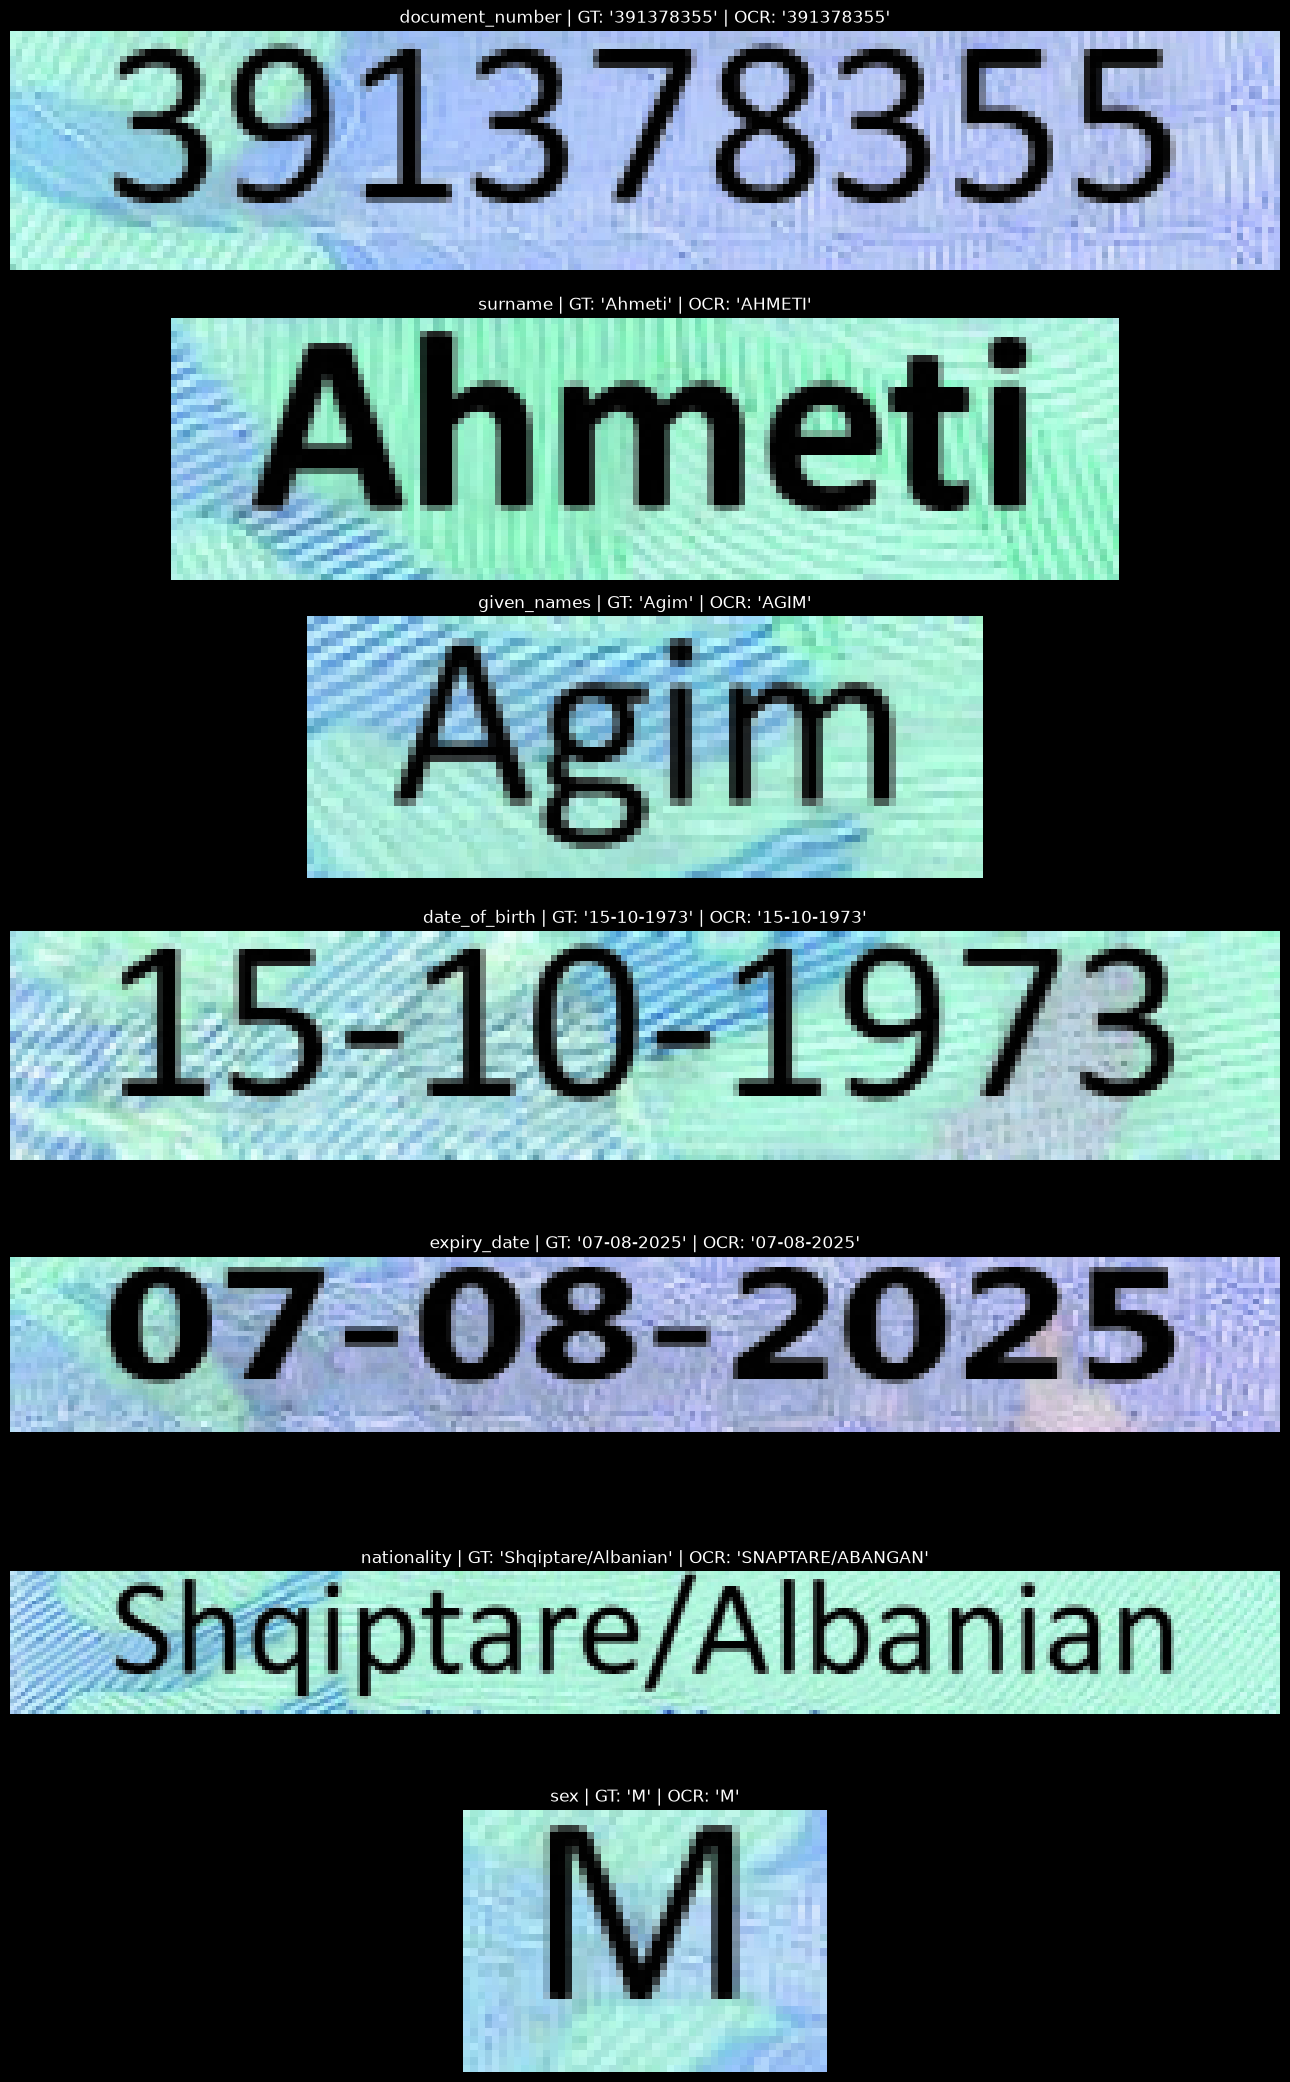

In [60]:

figure, axes = plt.subplots(
    len(training_field_results),
    1,
    figsize=(13, 3 * len(training_field_results)),
)

for axis, result_row in zip(
    axes,
    training_field_result_rows,
):
    canonical_field_name = result_row[
        "canonical_field"
    ]

    axis.imshow(
        training_field_crops_rgb[
            canonical_field_name
        ]
    )

    axis.set_title(
        f"{canonical_field_name} | "
        f"GT: {result_row['ground_truth']!r} | "
        f"OCR: {result_row['raw_prediction']!r}"
    )

    axis.axis("off")

plt.tight_layout()
plt.show()

In [61]:
def classify_preview_outcome(result_row):
    if result_row["raw_exact_match"]:
        return "raw_exact"

    if result_row["casefold_preview_match"]:
        return "case_only_difference"

    return "recognition_error"


training_field_results["preview_outcome"] = (
    training_field_results.apply(
        classify_preview_outcome,
        axis=1,
    )
)

preview_outcome_counts = (
    training_field_results["preview_outcome"]
    .value_counts()
)

preview_outcome_counts

preview_outcome
raw_exact               4
case_only_difference    2
recognition_error       1
Name: count, dtype: int64

## First-identity observations

- The recognizer correctly read the document number, both dates, and sex.
- The surname and given names were recognized correctly except for case.
- Case differences are handled by the approved normalization contract.
- Nationality contains genuine character errors and remains incorrect after
  case folding.
- One training identity is insufficient for estimating model accuracy.
- We should preserve these raw predictions and test more identities before
  changing the model, crop rules, or decoding settings.